In [1]:
import matplotlib.pyplot as plt
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import warnings
import pandas as pd
import os
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from enum import Enum
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from collections import defaultdict
import os
import time # 描画のために追加
from stable_baselines3 import PPO


In [2]:
# ActionTypeの定義 (元のノートブックにある場合)
class ActionType(Enum):
    DO_NOTHING = 0
    DO_TASK = 1

In [3]:
import gymnasium as gym # gymnasium を gym という名前でインポート
from gymnasium import spaces
import numpy as np
import time
import warnings # ユーザーコードにあったため追加
# from enum import Enum # ActionType などで Enum を使う場合は必要

# ActionType の定義 (もしあれば、このクラス定義の前に配置)
# class ActionType(Enum):
#     ACTION_0 = 0
#     ACTION_1 = 1
#     ACTION_2 = 2 # n_actions=3 の場合

class SimplifiedTaskJITAIEnv(gym.Env):
    metadata = {'render_modes': ['human', 'rgb_array'], 'render_fps': 4} # rgb_arrayも追加しておくと良い

    def __init__(self,
                 n_actions=3,
                 max_episode_length=90,
                 seed=0,
                 co_score=0.5,
                 total_task_work=400.0,
                 delta_d_base=0.02,
                 epsilon_d_base=0.05,
                 D_threshold_base=0.1,
                 d_increase_on_inaction_base=0.002,
                 co_effect_on_d_increase_inaction_multiplier=-0.5,
                 inaction_steps_threshold=5,
                 base_prob_start_action_base=0.6,
                 intervention_boost_to_prob_start_base=[0.0, 0.1, 0.25],
                 urgency_factor_base=0.3,
                 mu_s_base=4.1,
                 rho1_base=2.0,
                 rho2_base=5.0,
                 co_effect_on_delta_d_multiplier=0.3,
                 co_effect_on_epsilon_d_multiplier=0.5,
                 co_effect_on_D_threshold_multiplier=1.5,
                 co_effect_on_base_prob_start_multiplier=0.2,
                 co_effect_on_intervention_boost_multiplier=0.1,
                 co_effect_on_urgency_factor_multiplier=-0.4,
                 co_effect_on_mu_s_multiplier=0.2,
                 co_effect_on_rho1_multiplier=0.1,
                 co_effect_on_rho2_multiplier=0.1,
                 init_d=0.1,
                 chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
                 n_version=0,
                 s_noise_std_base=0.0,
                 co_effect_on_s_noise_std_multiplier=0.0,
                 intervention_cost=[0.0,0.01,0.2],
                 # ★★★ ここに新しい引数を追加します ★★★
                 habituation_increment_weak=0.02,
                 habituation_increment_strong=0.05,
                 habituation_decay=0.01,
                 render_mode=None): # <<-- render_mode 引数を追加
        super().__init__()

        self.max_episode_length = max_episode_length
        self.n_actions = n_actions
        self.chosen_obs_names = chosen_obs_names
        self.n_version = n_version

        self.co_score = np.clip(co_score, 0.0, 1.0)
        self.current_CO = self.co_score # __init__ で一度設定

        self.delta_d_base = delta_d_base
        self.epsilon_d_base = epsilon_d_base
        self.D_threshold_base = D_threshold_base
        self.d_increase_on_inaction_base = d_increase_on_inaction_base
        self.co_effect_on_d_increase_inaction_multiplier = co_effect_on_d_increase_inaction_multiplier
        self.inaction_steps_threshold = inaction_steps_threshold

        self.base_prob_start_action_base = base_prob_start_action_base
        self.intervention_boost_to_prob_start_base = np.array(intervention_boost_to_prob_start_base)
        if len(self.intervention_boost_to_prob_start_base) != n_actions:
            raise ValueError("Length of intervention_boost_to_prob_start_base must match n_actions.")
        self.urgency_factor_base = urgency_factor_base
        self.mu_s_base = mu_s_base
        self.rho1_base = rho1_base
        self.rho2_base = rho2_base
        self.total_task_work = total_task_work
        self.s_noise_std_base = s_noise_std_base

        self.co_effect_on_delta_d_multiplier = co_effect_on_delta_d_multiplier
        self.co_effect_on_epsilon_d_multiplier = co_effect_on_epsilon_d_multiplier
        self.co_effect_on_D_threshold_multiplier = co_effect_on_D_threshold_multiplier
        self.co_effect_on_base_prob_start_multiplier = co_effect_on_base_prob_start_multiplier
        self.co_effect_on_intervention_boost_multiplier = co_effect_on_intervention_boost_multiplier
        self.co_effect_on_urgency_factor_multiplier = co_effect_on_urgency_factor_multiplier
        self.co_effect_on_mu_s_multiplier = co_effect_on_mu_s_multiplier
        self.co_effect_on_rho1_multiplier = co_effect_on_rho1_multiplier
        self.co_effect_on_rho2_multiplier = co_effect_on_rho2_multiplier
        self.co_effect_on_s_noise_std_multiplier = co_effect_on_s_noise_std_multiplier

        self.init_d = init_d
        self.init_s = 0.0
        self.init_task_progress = 0.0
        
       
        self.intervention_costs = np.array(intervention_cost)
        if len(self.intervention_costs) != n_actions:
            raise ValueError("Length of intervention_costs must match n_actions.")
        # ★★★【修正箇所】この位置に「介入慣れ」のパラメータ定義を移動してくる ★★★
        # --- 介入慣れ (Habituation) 用のパラメータと状態変数を追加 ---
        self.habituation_level = 0.0 # 現在の慣れレベル (0.0から1.0)
        
        self.habituation_decay = 0.01   # 1ステップあたりの慣れ減少量 (非介入時)
        self.max_habituation_level = 1.0  # 慣れレベルの上限
        # --- ここまで移動 ---
# ↓↓↓ 古い self.habituation_increment の行を、以下の2行に置き換える ↓↓↓
        # self.habituation_increment = 0.05 # ← この行を削除またはコメントアウト
        self.habituation_increment_weak = habituation_increment_weak     # 弱い介入での慣れ増加量
        self.habituation_increment_strong = habituation_increment_strong   # 強い介入での慣れ増加量

        self.seed = seed # 初期シード
        self.rng1 = np.random.default_rng(self.seed) # __init__で一度初期化

        self.current_t = 0
        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.consecutive_inaction_steps = 0

        self.action_space = spaces.Discrete(self.n_actions)
        min_obs_values, max_obs_values = self.extract_min_max()
        self.observation_space = spaces.Box(
            low=np.array(min_obs_values, dtype=np.float32),
            high=np.array(max_obs_values, dtype=np.float32),
            dtype=np.float32
        )
        self._initialize_operational_params() # 初期パラメータ設定

        # --- レンダリングモード設定 ---
        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        # --- ここまで ---

        # --- レンダリング用に直前の情報を保持する変数 (適宜追加) ---
        self.last_agent_action = None # agent_action を保持
        self.last_step_reward = 0.0
        # --- ここまで ---


    def _initialize_operational_params(self):
        # このメソッドは reset で呼ばれるため、co_score に応じた調整は reset で行う
        self.delta_d, self.epsilon_d, self.D_threshold = 0.0, 0.0, 0.0
        self.base_prob_start_action = 0.0
        self.intervention_boost_to_prob_start = np.zeros(self.n_actions)
        self.urgency_factor = 0.0
        self.mu_s, self.rho1, self.rho2 = 0.0, 0.0, 0.0
        self.s_noise_std = 0.0

    def _adjust_param(self, base_val, multiplier, co_factor):
        return base_val * (1 + co_factor * multiplier)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None: # 引数でseedが指定されたら、それを使用
            self.seed = seed
        # self.seed はインスタンスの初期seed、または引数で与えられたseed
        # rngの再初期化時は、エピソードごとに異なる状態にするため工夫が必要な場合もあるが、
        # Gymnasiumのsuper().reset(seed=seed)が内部で適切に処理してくれることを期待する。
        # ここでは、ユーザーの元のコードに合わせてrng1を再生成する
        self.rng1 = np.random.default_rng(self.seed) # self.seed を使う

        self._initialize_operational_params() # パラメータを一度リセット
        co_factor = self.co_score - 0.5 # co_score は __init__ で設定されたものを使用

        self.D_threshold = np.clip(self.D_threshold_base, 0.001, 0.999)
        
        self.delta_d = np.clip(self._adjust_param(self.delta_d_base, self.co_effect_on_delta_d_multiplier, co_factor), 0.0, 0.999)
        self.epsilon_d = np.clip(self._adjust_param(self.epsilon_d_base, self.co_effect_on_epsilon_d_multiplier, co_factor), 0.0, 0.999)

        self.base_prob_start_action = np.clip(self._adjust_param(self.base_prob_start_action_base, self.co_effect_on_base_prob_start_multiplier, co_factor), 0.01, 0.99)
        boost_adjustment = (1 + co_factor * self.co_effect_on_intervention_boost_multiplier)
        self.intervention_boost_to_prob_start = np.clip(self.intervention_boost_to_prob_start_base * boost_adjustment, 0.0, 0.5)
        self.urgency_factor = self._adjust_param(self.urgency_factor_base, self.co_effect_on_urgency_factor_multiplier, co_factor)
        self.urgency_factor = np.clip(self.urgency_factor, -0.5, 0.5) # 元のコードではマイナスもあり得る
        self.mu_s = np.clip(self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor), 0.1, None) # 下限0.1
        self.rho1 = np.clip(self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor), 0.0, None) # 下限0.0
        self.rho2 = np.clip(self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor), 0.0, None) # 下限0.0

        if self.n_version == 1:
            self.s_noise_std = np.clip(self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor), 0.0, None) # 下限0.0
        else:
            self.s_noise_std = 0.0

        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.current_t = 0
        self.consecutive_inaction_steps = 0
        self.habituation_level = 0.0 # <<-- エピソード開始時に慣れレベルをリセット

        # レンダリング用変数のリセット
        self.last_agent_action = None
        self.last_step_reward = 0.0

        obs = self._get_observation()
        info = self._get_info() # 最初に基本情報を取得
        info.update({"message": "Environment reset."}) # メッセージを追加

        # reset時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()
            
        return obs, info

    def step(self, agent_action):
        a = int(agent_action)
         # --- ★介入慣れレベルの更新ロジックを追加★ ---
     
    # --- ★介入慣れレベルの更新ロジックを修正★ ---
        # if a == 1 or a == 2: ... else: ... の部分を以下に置き換える
        if a == 1: # 弱い介入が選択された場合
            self.habituation_level += self.habituation_increment_weak
        elif a == 2: # 強い介入が選択された場合
            self.habituation_level += self.habituation_increment_strong
        else: # 介入なし(行動0)が選択された場合
            self.habituation_level -= self.habituation_decay
        
        # 慣れレベルが 0.0 から上限値の範囲に収まるように調整
        self.habituation_level = np.clip(self.habituation_level, 0.0, self.max_habituation_level)
        # --- ここまで修正 ---


        if not (0 <= a < self.n_actions): # Action space validation
            raise ValueError(f"Action {a} is out of range for n_actions={self.n_actions}")

        self.last_agent_action = a # 直前の行動を保存

        task_progress_t = self.TaskProgress # ステップ開始時の進捗

        time_remaining_normalized = (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        urgency_effect_on_prob_start = 0.0
        urgency_threshold = 0.3 # この値はパラメータ化しても良い
        if time_remaining_normalized < urgency_threshold and time_remaining_normalized >= 0:
            urgency_level = 1.0 - (time_remaining_normalized / urgency_threshold)
            urgency_effect_on_prob_start = self.urgency_factor * urgency_level



        # --- ★介入慣れによる効果低減を計算★ ---
        effectiveness_multiplier = 1.0 - (self.habituation_level / self.max_habituation_level)
        
        actual_boost = self.intervention_boost_to_prob_start[a] * effectiveness_multiplier
        # 注意: 行動0のboostは元々0なので、この計算は実質的に介入行動(1, 2)にのみ影響

        

        prob_start_action_calculated = self.base_prob_start_action \
                                     + actual_boost \
                                     + urgency_effect_on_prob_start
        prob_start_action_calculated = np.clip(prob_start_action_calculated, 0.01, 0.99)






        s_this_step = 0.0
        action_started_this_step = False
        if self.rng1.random() < prob_start_action_calculated: # rng1を使用
            action_started_this_step = True
            s_next_mu_calculated = self.mu_s
            if a == 1: s_next_mu_calculated += self.rho1 # 行動タイプ1 (介入1と仮定)
            elif a == 2: s_next_mu_calculated += self.rho2 # 行動タイプ2 (介入2と仮定)
            # 注意: a==0 の場合は s_next_mu_calculated は self.mu_s のまま。これが意図通りか確認。
            
            s_final_next_if_started = s_next_mu_calculated
            if self.n_version == 1 and self.s_noise_std > 0:
                s_final_next_if_started = max(0.0, self.rng1.normal(s_next_mu_calculated, self.s_noise_std)) # rng1を使用
            s_this_step = max(0.0, s_final_next_if_started)
        self.S = s_this_step

        d_increased_this_step_due_to_inaction = 0.0 # 初期化
        if not action_started_this_step:
            self.consecutive_inaction_steps += 1
            if self.consecutive_inaction_steps >= self.inaction_steps_threshold: # 閾値以上でD増加
                co_factor = self.co_score - 0.5
                actual_d_increase = self._adjust_param(
                    self.d_increase_on_inaction_base,
                    self.co_effect_on_d_increase_inaction_multiplier,
                    co_factor
                )
                actual_d_increase = max(0, actual_d_increase) # 負の増加はしない
                self.D += actual_d_increase
                d_increased_this_step_due_to_inaction = actual_d_increase
        else:
            self.consecutive_inaction_steps = 0
        self.D = np.clip(self.D, 0.0, 1.0)


        if self.total_task_work > 1e-9: # ゼロ除算を避ける
            progress_this_step = self.S / self.total_task_work
            self.TaskProgress = np.clip(task_progress_t + progress_this_step, 0.0, 1.0)
        else: # total_task_work がほぼ0なら、Sが正なら即完了とみなすか、進捗なしとするか
            self.TaskProgress = 1.0 if self.S > 0 else task_progress_t


        step_reward = 0.0
        progress_made_in_step = self.TaskProgress - task_progress_t
        reward_scale_factor = 20.0 # パラメータ化しても良い
        step_reward += progress_made_in_step * reward_scale_factor
        
        task_completed_this_step = (task_progress_t < 1.0 and self.TaskProgress >= 1.0)
        if task_completed_this_step:
            step_reward += 100.0 # タスク完了ボーナス

        # stepメソッド内
        # ★変更点: 行動aをインデックスとして使い、対応するコストを引く
        step_reward -= self.intervention_costs[a]
        
        self.last_step_reward = step_reward # 直前の報酬を保存

        terminated = False
        truncated = False
        
        current_info = self._get_info() # 情報を先に取得
        current_info["action_taken"] = a # info に agent_action を含める
        current_info["action_started_this_step"] = action_started_this_step
        current_info["prob_start_action"] = prob_start_action_calculated
        current_info["urgency_effect_on_prob_start"] = urgency_effect_on_prob_start
        current_info["d_increased_due_to_inaction"] = d_increased_this_step_due_to_inaction
        current_info["task_completed_this_step"] = task_completed_this_step # このステップで完了したか


        if task_completed_this_step:
            terminated = True
            current_info['task_completed'] = True # Gymnasiumの info['TimeLimit.truncated'] と区別するため

        if self.D >= self.D_threshold and not terminated: # Dが閾値を超えたら終了 (タスク未完了の場合)
            terminated = True
            current_info['disengaged'] = True # 離脱を示すフラグ
            step_reward -= 20.0 # 離脱ペナルティ
            self.S = 0.0 # 行動量を0に (意図による)
        
        self.current_t += 1
        if self.current_t >= self.max_episode_length and not terminated: # 最大ステップ到達で打ち切り
            truncated = True
            current_info['TimeLimit.truncated'] = True # Gymnasium標準のキー
            if self.TaskProgress < 1.0: # 未完了ならペナルティ
                step_reward -= 10.0

        observation = self._get_observation()
        
        # step時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()

        return observation, float(step_reward), terminated, truncated, current_info

    def _get_observation(self):
        obs_dict = {
            'D': self.D, 'S': self.S, 'TP': self.TaskProgress, 'CO': self.current_CO,
            'TR': (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            'Habituation': self.habituation_level # <<-- ★追加
        }
        obs_values = []
        for obs_name in self.chosen_obs_names:
            if obs_name in obs_dict:
                obs_values.append(obs_dict[obs_name])
            elif obs_name == 'T_parity':
                obs_values.append(self.get_T_parity())
            else:
                obs_values.append(0.0) # 未知の観測名は0
                warnings.warn(f"Unknown obs_name '{obs_name}' in chosen_obs_names. Appending 0.0.", UserWarning)
        return np.array(obs_values, dtype=np.float32)

    def _get_info(self):
        # このメソッドは reset と step の両方から呼ばれるため、
        # step固有の情報（prob_start_actionなど）はstepメソッド内でcurrent_infoに追加する
        base_info = {
            "current_D": self.D, "current_S": self.S,
            "current_TaskProgress": self.TaskProgress, "current_CO": self.current_CO,
            "current_t": self.current_t,
            "time_remaining_normalized": (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            "consecutive_inaction_steps": self.consecutive_inaction_steps,
            "adjusted_D_threshold": getattr(self, 'D_threshold', None),
            "current_Habituation": self.habituation_level, # <<-- ★この行を追加
            # resetで計算されるパラメータをinfoに含めたい場合、ここに追加
            "D_threshold_operational": self.D_threshold,
            "base_prob_start_action_operational": self.base_prob_start_action,
            # ... など
        }
        return base_info

    def extract_min_max(self):
        # このメソッドは複雑なため、ユーザー様の実装を信頼し、ここでは変更しません。
        # chosen_obs_names に合わせて min/max を正しく返すことが重要です。
        min_values = []; max_values = []
        co_factor_extrema = 0.5 # co_score が 0 または 1 の場合を想定 (0.5 - 0.5 = 0, 0.5 + 0.5 = 1)

        # mu_s の取りうる範囲を推定 (簡略化のため、rhoは最大のものだけ考慮)
        mu_s_adj_plus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor_extrema)
        mu_s_adj_minus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, -co_factor_extrema)
        max_mu_s_base_adjusted = max(mu_s_adj_plus, mu_s_adj_minus, self.mu_s_base)
        
        rho1_adj_plus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor_extrema)
        rho1_adj_minus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, -co_factor_extrema)
        max_rho1_adjusted = max(rho1_adj_plus, rho1_adj_minus, self.rho1_base)

        rho2_adj_plus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor_extrema)
        rho2_adj_minus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, -co_factor_extrema)
        max_rho2_adjusted = max(rho2_adj_plus, rho2_adj_minus, self.rho2_base)

        max_s_component = max(0, max_mu_s_base_adjusted) + max(0, max_rho1_adjusted, max_rho2_adjusted) # 簡略化: mu_s + max(rho)

        s_noise_std_adj_plus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor_extrema) if self.n_version == 1 else 0.0
        s_noise_std_adj_minus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, -co_factor_extrema) if self.n_version == 1 else 0.0
        max_s_noise_std_adj = max(0, s_noise_std_adj_plus, s_noise_std_adj_minus, self.s_noise_std_base if self.n_version == 1 else 0.0)

        # Sの最大値の推定 (ノイズも考慮)
        # 非常に大まかな推定: 平均的な最大値 + ノイズの数標準偏差分 (例: 3*std)
        # より正確には、s_next_mu_calculated と s_noise_std の関係から求める必要がある
        max_s_estimate = max(0.1, max_s_component + (3 * max_s_noise_std_adj if self.n_version == 1 else 0.0) )


        for check_obs in self.chosen_obs_names:
            if check_obs == 'D': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'S': min_values.append(0.0); max_values.append(max_s_estimate) # 推定値を使用
            elif check_obs == 'TP': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'CO': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'TR': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'T_parity': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'Habituation': min_values.append(0.0); max_values.append(self.max_habituation_level) # <<-- ★追加
            else: raise ValueError(f"Unknown obs_name '{check_obs}' in chosen_obs_names for extract_min_max.")
        return min_values, max_values

    def get_T_parity(self):
        return float((self.current_t % 2) == 0) # 0.0 または 1.0

    def render(self):
        if self.render_mode == "human":
            print(f"\n--- Time: {self.current_t} / {self.max_episode_length} ---")
            print(f"  CO Score: {self.co_score:.2f}")
            if self.last_agent_action is not None:
                print(f"  Last Action Taken by Agent: {self.last_agent_action}")
            else:
                print("  Last Action Taken by Agent: None (Start of Episode)")
            print(f"  Last Reward Received: {self.last_step_reward:.3f}") # last_step_reward を参照
            print(f"  D: {self.D:.3f} (Threshold: {self.D_threshold:.3f})")
            print(f"  S: {self.S:.3f}")
            print(f"  TaskProgress (TP): {self.TaskProgress:.3f}")
            print(f"  Consecutive Inaction: {self.consecutive_inaction_steps}")
            print(f"  Habituation Level: {self.habituation_level:.3f}") # <<-- ★追加
            
            # 内部状態 (デバッグ用など)
            # print(f"  Prob Start Action: {getattr(self, 'prob_start_action_calculated', 'N/A')}") # step内で計算
            # print(f"  Action Started This Step: {getattr(self, 'action_started_this_step', 'N/A')}") # step内で計算
            
            # 終了状態の表示 (stepメソッドのterminated/truncatedロジックと整合させる)
            is_terminated = False
            is_truncated = False
            if getattr(self, 'task_completed_this_step', False) or (getattr(self, 'TaskProgress',0) >= 1.0): # stepメソッドでtask_completed_this_stepフラグを設定するか、TaskProgressを見る
                is_terminated = True
                print("  Status: TASK COMPLETED")
            elif getattr(self, 'D', 0) >= getattr(self, 'D_threshold', 1.0) : # Dが閾値以上
                is_terminated = True
                print("  Status: DISENGAGED (D exceeded threshold)")

            if self.current_t >= self.max_episode_length and not is_terminated: # 最大ステップ到達
                is_truncated = True
                print("  Status: TIMELIMIT TRUNCATED")
            
            if is_terminated or is_truncated:
                print("  --- EPISODE ENDED ---")

            time.sleep(0.1) # 描画速度の調整

    def close(self):
        pass

# --- 以下のプロット関数はユーザー提供のものをそのまま利用 ---
# def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
#     ...
# def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
#     ...

In [4]:
# --- 固定ポリシーシミュレーション結果用のプロット関数 ---
def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
    # ... (この関数は以前提供したものと同じ) ...
    legend_elements_subplot = {}
    ax.set_title(plot_title)
    ax.set_ylabel(var_name)
    ax.grid(True, linestyle='--', alpha=0.7)
    for co_val in co_scores:
        df_co_specific = df_steps[df_steps['co_score'] == co_val]
        if var_name in df_co_specific.columns and not df_co_specific.empty:
            try:
                pivot_df = df_co_specific.pivot_table(index='step', columns='run_id', values=var_name)
                avg_series = pivot_df.mean(axis=1)
                if not avg_series.empty:
                    line, = ax.plot(avg_series.index, avg_series.values, label=f'co={co_val:.1f}')
                    legend_elements_subplot[f'co={co_val:.1f}'] = line
                    if var_name == 'D' and 'D_threshold_value' in df_co_specific.columns:
                        valid_thresholds = df_co_specific['D_threshold_value'].dropna()
                        if not valid_thresholds.empty:
                            d_thresh_for_co = valid_thresholds.iloc[0]
                            line_color = line.get_color()
                            threshold_legend_label = f'D Thresh (co={co_val:.1f})'
                            ax.axhline(d_thresh_for_co, color=line_color, linestyle='--', linewidth=1.2, alpha=0.9)
                            if threshold_legend_label not in legend_elements_subplot:
                                dummy_line, = ax.plot([], [], color=line_color, linestyle='--', linewidth=1.2, label=threshold_legend_label)
                                legend_elements_subplot[threshold_legend_label] = dummy_line
            except Exception as e:
                print(f"プロットエラー (サブプロット内関数): {var_name} for co_score={co_val}. Error: {e}")
    if show_xlabel:
        ax.set_xlabel('Step')
    if legend_elements_subplot:
        sorted_legend_items = sorted(legend_elements_subplot.items(), key=lambda item: item[0])
        ax.legend([item[1] for item in sorted_legend_items], [item[0] for item in sorted_legend_items], title='Legend', loc='best', fontsize='small')

# --- 強化学習エージェントの行動可視化用のプロット関数 ---
def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
    # ... (この関数は以前提供したものと同じ) ...
    episode_data = df_all_eval_steps[df_all_eval_steps['episode_id'] == episode_id_to_plot].copy()
    if episode_data.empty:
        print(f"エピソード {episode_id_to_plot} のデータがありません。")
        return

    co_score_episode = episode_data['CO'].iloc[0] if 'CO' in episode_data.columns and not episode_data['CO'].empty else env_config.get("co_score", 0.5)

    if 'D_threshold_value' in episode_data.columns and not episode_data['D_threshold_value'].isnull().all():
         d_threshold = episode_data['D_threshold_value'].dropna().iloc[0]
    else:
        co_factor = co_score_episode - 0.5
        d_thresh_base = env_config.get('D_threshold_base', 0.2)
        # D閾値がco_scoreに依存しない共通値の場合 (co_effect_on_D_threshold_multiplier を使わない)
        d_threshold = np.clip(d_thresh_base, 0.001, 0.999)
        # もしco_score依存にする場合は以下のコメントアウトを解除し、引数やenv_config_baseのキーを確認
        # co_eff_d_thresh = env_config.get('co_effect_on_D_threshold_multiplier', 0) # 0なら影響なし
        # adjusted_d_threshold = d_thresh_base * (1 + co_factor * co_eff_d_thresh)
        # d_threshold = np.clip(adjusted_d_threshold, 0.001, 0.999)


    intervention_styles = {
        0: {'color': 'lightgray', 'linestyle': ':', 'label': 'No Int.'},
        1: {'color': 'skyblue', 'linestyle': '--', 'label': 'Weak Int.'},
        2: {'color': 'salmon', 'linestyle': '-.', 'label': 'Strong Int.'}
    }
    num_subplots = 4
    fig, axes = plt.subplots(num_subplots, 1, figsize=(15, num_subplots * 3), sharex=True)
    fig.suptitle(f'RL Agent Behavior - Episode {episode_id_to_plot} (CO={co_score_episode:.2f})', fontsize=16)

    axes[0].plot(episode_data['step'], episode_data['D'], marker='.', linestyle='-', color='red', label='D (Risk)')
    axes[0].axhline(y=d_threshold, color='red', linestyle=':', linewidth=1.5, label=f'D Threshold ({d_threshold:.2f})')
    axes[0].set_ylabel('D (Risk)')
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].legend(loc='upper right')
    axes[0].grid(True, linestyle=':', alpha=0.7)

    axes[1].plot(episode_data['step'], episode_data['TP'], marker='.', linestyle='-', color='blue', label='TP (Progress)')
    axes[1].set_ylabel('TP (Progress)')
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].legend(loc='upper right')
    axes[1].grid(True, linestyle=':', alpha=0.7)
    
    axes[2].plot(episode_data['step'], episode_data['S'], marker='.', linestyle='-', color='green', label='S (Action Volume)')
    axes[2].set_ylabel('S (Action Volume)')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, linestyle=':', alpha=0.7)
    #axes[2].set_xlabel('Step in Episode')
# --- ★★★ 修正点3: Habituation (H) のための新しいサブプロットを追加 ★★★ ---
    # 'Habituation' 列がデータに存在するか確認
    if 'Habituation' in episode_data.columns:
        # env_configからmax_habituation_levelを取得、なければデフォルト値1.0を使用
        max_h_level = env_config.get('max_habituation_level', 1.0)

        axes[3].plot(episode_data['step'], episode_data['Habituation'], marker='.', linestyle='-', color='purple', label='H (Habituation)')
        axes[3].set_ylabel('Habituation Level')
        axes[3].set_ylim(-0.05, max_h_level + 0.05) # Y軸の上限を調整
        axes[3].legend(loc='upper right')
        axes[3].grid(True, linestyle=':', alpha=0.7)
        axes[3].set_xlabel('Step in Episode') # ← X軸ラベルは一番下のグラフに設定
    else:
        axes[3].text(0.5, 0.5, "'Habituation' data not found in evaluation steps.", 
                     ha='center', va='center', transform=axes[3].transAxes)
        axes[3].set_xlabel('Step in Episode')
    # --- ここまで追加 ---

    
    action_legend_handles_generated = {}
    for i in range(num_subplots):
        for _, row in episode_data.iterrows():
            action = int(row['action_taken'])
            step = row['step']
            style = intervention_styles.get(action)
            if style:
                axes[i].axvline(x=step, color=style['color'], linestyle=style['linestyle'], alpha=0.6, linewidth=1.5)
                if style['label'] not in action_legend_handles_generated:
                    action_legend_handles_generated[style['label']] = plt.Line2D([0], [0], color=style['color'], linestyle=style['linestyle'], linewidth=1.5)
    
    handles, labels = [], []
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for handle, label_text in zip(h,l):
            if label_text not in labels: handles.append(handle); labels.append(label_text)
    for label_text, handle in action_legend_handles_generated.items():
        if label_text not in labels: handles.append(handle); labels.append(label_text)
    if handles: fig.legend(handles, labels, loc='lower center', ncol=min(len(handles), 4), bbox_to_anchor=(0.5, 0.05 / num_subplots ))
    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.show()

In [5]:
# ==============================================================================
# ステップ3: シミュレーションの実行部分
# ==============================================================================
if __name__ == '__main__': # Jupyter Notebookでは通常このブロックは不要で、インデントを一段階浅くする
    RUN_FIXED_POLICY_SIMULATIONS = True
    RUN_RL_TRAINING_AND_EVALUATION = True # RLトレーニングはここでは実行しない想定

    # --- 1. env_config_base の定義 ---
    env_config_base = {
        "n_actions": 3, "max_episode_length": 90, "total_task_work": 400.0,
        "delta_d_base": 0.02, "epsilon_d_base": 0.05, "D_threshold_base": 0.10,
        "d_increase_on_inaction_base": 0.01, "co_effect_on_d_increase_inaction_multiplier": -0.5,
        "inaction_steps_threshold": 3, "base_prob_start_action_base": 0.6,
        "intervention_boost_to_prob_start_base": [0.0, 0.2, 0.25], "urgency_factor_base": 0.3,
        "mu_s_base": 4.1, "rho1_base": 2.0, "rho2_base": 5.0,
        "co_effect_on_delta_d_multiplier": 0.3, "co_effect_on_epsilon_d_multiplier": 0.5,
        "co_effect_on_D_threshold_multiplier": 1.5, 
        "co_effect_on_base_prob_start_multiplier": 0.2, "co_effect_on_intervention_boost_multiplier": 0.1,
        "co_effect_on_urgency_factor_multiplier": -0.4, "co_effect_on_mu_s_multiplier": 0.2,
        "co_effect_on_rho1_multiplier": 0.1, "co_effect_on_rho2_multiplier": 0.1,
        "intervention_cost": [0.0, 0.01, 0.2], "init_d": 0.0,
        "chosen_obs_names": ['D', 'S', 'TP', 'CO', 'TR', 'T_parity','Habituation'],
        "n_version": 0, "s_noise_std_base": 0.0, "co_effect_on_s_noise_std_multiplier": 0.0
    }

    if RUN_FIXED_POLICY_SIMULATIONS:
        print("--- 固定ポリシーでのシミュレーション開始 ---")
        
        # テスト用のパラメータ定義
        actions_to_simulate_list_render_test = [0,1,2]
        co_score_levels_to_test_render_test = [0.2,0.5,0.8]
        num_runs_per_condition_render_test = 100 # 1回に減らして確認

        # 本格的なシミュレーション用のパラメータ (今回は使わない)
        # actions_to_simulate_list = [0, 1, 2]
        # co_score_levels_to_test = [0.2, 0.5, 0.8]
        # num_runs_per_condition = 100

        all_step_data_list = []
        episode_summary_list = []
        
        # print("レンダリングを含むシミュレーションを開始します...") # メッセージ重複するのでコメントアウト

        for current_simulated_action in actions_to_simulate_list_render_test:
            print(f"\n===== シミュレーション中: Simulated Action = {current_simulated_action} =====")
            for co_score_val in co_score_levels_to_test_render_test:
                print(f"--- CO Score = {co_score_val} ---")
                current_env_params = env_config_base.copy()
                current_env_params["co_score"] = co_score_val
                # current_env_params["seed"] = ... # run ごとに異なるseedを使いたい場合はここで設定しない

                for i in range(num_runs_per_condition_render_test):
                    run_seed = i # 各runに異なるseedを設定 (またはより複雑なseed生成)
                    print(f"\n<<< Run ID: {i} (Seed: {run_seed}), SimAction: {current_simulated_action}, CO: {co_score_val} 開始 >>>")
                    
                    try:
                        env_fixed_policy = SimplifiedTaskJITAIEnv(
                            **current_env_params,
                            seed=run_seed, # runごとのseedを渡す
                            render_mode='human' 
                        )
                        
                        obs, info = env_fixed_policy.reset(seed=run_seed) # resetにもseedを渡す
                        terminated, truncated = False, False # episode_steps は削除しました（run_idで追えるため）
                        episode_steps_count = 0 # 実際のステップ数をカウント

                        current_episode_reward = 0.0

                        while not (terminated or truncated):
                            action_to_take_in_env = current_simulated_action
                            obs, reward, terminated, truncated, info_step = env_fixed_policy.step(action_to_take_in_env)
                            
                            # renderメソッド内で詳細情報を表示するために、info_stepを一時保存する案
                            #env_fixed_policy.step_info_for_render = info_step
                            current_episode_reward += reward # ★★★ 2. ステップごとの報酬を加算 ★★★
                            # 明示的にrenderを呼び出す場合
                           # env_fixed_policy.render() 

                            episode_steps_count += 1

                            step_data_entry = {
                                'run_id': i, 'simulated_action': current_simulated_action,
                                'total_reward': current_episode_reward, # ★★★ 3. 計算した総報酬を追加 ★★★
                                'co_score': co_score_val, 'step': episode_steps_count, # episode_steps_count を使用
                                'current_t_env': env_fixed_policy.current_t, 'D': env_fixed_policy.D, 
                                'S': env_fixed_policy.S, 'TP': env_fixed_policy.TaskProgress,
                                'action_taken_in_env': action_to_take_in_env,
                                'Habituation': info_step.get('current_Habituation'), # <<-- ★この行を追加
                                'reward_this_step': reward, # 追加:ステップごとの報酬
                                'terminated_this_step': terminated, # 追加
                                'truncated_this_step': truncated, # 追加
                                'D_threshold_value': info_step.get('adjusted_D_threshold'),
                                'prob_start_action_calculated': info_step.get('prob_start_action'),
                                'urgency_effect_on_prob_start': info_step.get('urgency_effect_on_prob_start'),
                                'consecutive_inaction_steps': env_fixed_policy.consecutive_inaction_steps,
                                'd_increased_this_step_due_to_inaction': info_step.get('d_increased_due_to_inaction', 0.0),
                                'action_started_this_step': info_step.get('action_started_this_step', False)
                            }
                            all_step_data_list.append(step_data_entry)

                        # エピソード終了時の情報取得
                        # stepループの最後でinfo_stepが最新なので、それを使う
                        task_completed = info_step.get('task_completed', False) or (env_fixed_policy.TaskProgress >= 1.0)
                        disengaged = info_step.get('disengaged', False)
                        # timed_out は truncated で表現される (TimeLimit.truncatedがTrue)
                        timed_out = truncated and not task_completed and not disengaged 

                        episode_summary_list.append({
                            'run_id': i, 'simulated_action': current_simulated_action, 'co_score': co_score_val,
                            'total_reward': current_episode_reward, # ← このキーと値を追加
                            'steps': episode_steps_count, 'completed': task_completed, 
                            'disengaged': disengaged, 'timed_out': timed_out,
                            'final_D': env_fixed_policy.D, 'final_TP': env_fixed_policy.TaskProgress
                        })
                        print(f">>> Run ID: {i} 終了: Steps={episode_steps_count}, Completed={task_completed}, Disengaged={disengaged}, TimedOut={timed_out} <<<")
                        env_fixed_policy.close()
                        
                    except NameError as ne:
                        print(f"NameError: {ne}. SimplifiedTaskJITAIEnvクラスが定義されていません。")
                        break 
                    except Exception as e:
                        print(f"シミュレーション中にエラーが発生しました (Run ID: {i}): {e}")
                        import traceback
                        traceback.print_exc() # 詳細なトレースバックを表示
                        continue # 次のrunへ
                else: # for i loop が break せずに完了した場合
                    continue # 次の co_score_val へ
                break # NameError などで co_score_val ループも抜ける
            else: # for co_score_val loop が break せずに完了した場合
                continue # 次の current_simulated_action へ
            break # NameError などで current_simulated_action ループも抜ける

        print("\nレンダリングを含む固定ポリシーシミュレーション完了。")
        
        # データフレームへの変換と保存 (任意)
        # import pandas as pd
        # if all_step_data_list:
        #     df_steps = pd.DataFrame(all_step_data_list)
        #     df_steps.to_csv("fixed_policy_step_data_render_test.csv", index=False)
        #     print("ステップデータが fixed_policy_step_data_render_test.csv に保存されました。")
        # if episode_summary_list:
        #     df_episodes = pd.DataFrame(episode_summary_list)
        #     df_episodes.to_csv("fixed_policy_episode_summary_render_test.csv", index=False)
        #     print("エピソードサマリーが fixed_policy_episode_summary_render_test.csv に保存されました。")

    # if RUN_RL_TRAINING_AND_EVALUATION:
    #     print("\n--- 強化学習のトレーニングと評価 (省略) ---")
        # ... (RL関連のコード)

--- 固定ポリシーでのシミュレーション開始 ---

===== シミュレーション中: Simulated Action = 0 =====
--- CO Score = 0.2 ---

<<< Run ID: 0 (Seed: 0), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 0 終了: Steps=90, Completed=False, Disengaged=False, TimedOut=True <<<

<<< Run ID: 1 (Seed: 1), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 1 終了: Steps=80, Completed=False, Disengaged=True, TimedOut=False <<<

<<< Run ID: 2 (Seed: 2), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 2 終了: Steps=90, Completed=False, Disengaged=False, TimedOut=True <<<

<<< Run ID: 3 (Seed: 3), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 3 終了: Steps=90, Completed=False, Disengaged=False, TimedOut=True <<<

<<< Run ID: 4 (Seed: 4), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 4 終了: Steps=90, Completed=False, Disengaged=False, TimedOut=True <<<

<<< Run ID: 5 (Seed: 5), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 5 終了: Steps=90, Completed=False, Disengaged=False, TimedOut=True <<<

<<< Run ID: 6 (Seed: 6), SimAction: 0, CO: 0.2 開始 >>>
>>> Run ID: 6 終了: Steps=83, Comple

シミュレーション結果の分析を開始します。

--- 集計表 (介入別、誠実性スコア別) ---
   simulated_action  co_score  num_episodes avg_total_reward avg_steps  \
0                 0       0.2           100            -1.52      85.3   
1                 0       0.5           100             1.75      89.7   
2                 0       0.8           100             3.14      89.7   
3                 1       0.2           100             9.22      89.2   
4                 1       0.5           100            35.54      89.3   
5                 1       0.8           100            94.80      85.9   
6                 2       0.2           100            92.86      73.6   
7                 2       0.5           100           106.23      68.9   
8                 2       0.8           100           107.28      63.6   

  completion_rate disengagement_rate timeout_rate  
0            0.0%              16.0%        84.0%  
1            0.0%               1.0%        99.0%  
2            0.0%               1.0%        99.0%  
3  

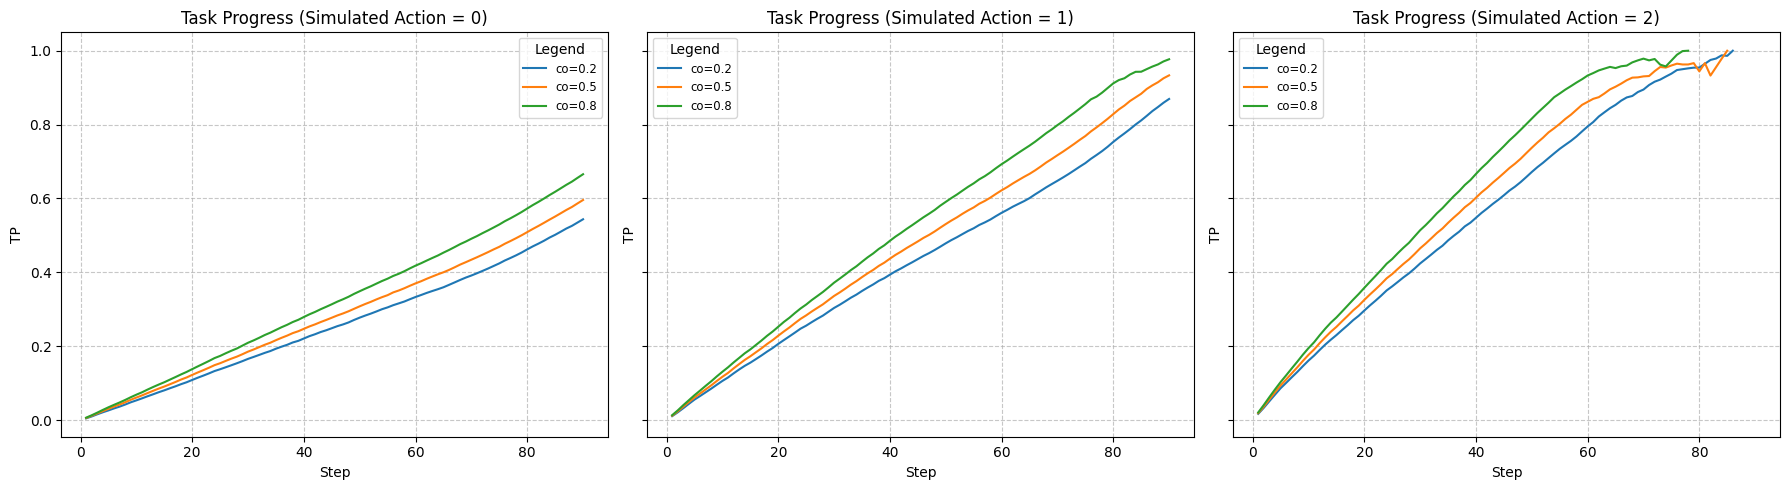

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# --- ステップ1: シミュレーション結果をDataFrameに変換 ---

# episode_summary_list と all_step_data_list にデータが収集されているか確認
if episode_summary_list and all_step_data_list:
    print("シミュレーション結果の分析を開始します。")
    
    # エピソードごとのサマリーデータをDataFrameに変換
    df_episodes = pd.DataFrame(episode_summary_list)
    
    # 全ステップの詳細データをDataFrameに変換
    df_steps = pd.DataFrame(all_step_data_list)

    # --- ステップ2: 集計表の作成と表示 ---
    
    print("\n--- 集計表 (介入別、誠実性スコア別) ---")
    
    # simulated_action と co_score でグループ化し、各指標を計算
    summary_table = df_episodes.groupby(['simulated_action', 'co_score']).agg(
        num_episodes=('run_id', 'count'),
        avg_total_reward=('total_reward', 'mean'),
        avg_steps=('steps', 'mean'),  # ← 追加
        completion_rate=('completed', 'mean'),
        disengagement_rate=('disengaged', 'mean'),
        timeout_rate=('timed_out', 'mean')
    ).reset_index()

    # パーセンテージ表示にフォーマット
    summary_table['avg_total_reward'] = summary_table['avg_total_reward'].map('{:.2f}'.format)
    summary_table['avg_steps'] = summary_table['avg_steps'].map('{:.1f}'.format)  # ← 追加
    summary_table['completion_rate'] = (summary_table['completion_rate'] * 100).map('{:.1f}%'.format)
    summary_table['disengagement_rate'] = (summary_table['disengagement_rate'] * 100).map('{:.1f}%'.format)
    summary_table['timeout_rate'] = (summary_table['timeout_rate'] * 100).map('{:.1f}%'.format)

    print(summary_table)
    
    # --- ステップ3: タスク進捗(TP)のプロット作成 ---
    
    print("\n--- タスク進捗(TP)の時系列グラフ ---")
    
    # 描画対象のシミュレーションされた行動（介入の種類）
    actions_to_plot = sorted(df_steps['simulated_action'].unique())
    # 描画対象のCOスコア
    co_scores_for_plot = sorted(df_steps['co_score'].unique())
    
    # 介入の種類ごとにグラフを作成
    # グラフの列数を設定 (最大3つまで)
    num_cols = min(len(actions_to_plot), 3)
    num_rows = (len(actions_to_plot) + num_cols - 1) // num_cols # 必要な行数を計算
    
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 6, num_rows * 5), sharex=True, sharey=True, squeeze=False)
    # axesを1次元配列に変換して扱いやすくする
    axes = axes.flatten()

    for i, action in enumerate(actions_to_plot):
        ax = axes[i]
        # 特定の行動のデータのみを抽出
        df_action_specific = df_steps[df_steps['simulated_action'] == action]
        
        # 以前定義したプロット関数をここで呼び出す
        plot_average_time_series_subplot(
            ax=ax, 
            df_steps=df_action_specific, 
            var_name='TP', 
            co_scores=co_scores_for_plot, 
            plot_title=f'Task Progress (Simulated Action = {action})',
            show_xlabel=True # 各グラフにX軸ラベルを表示
        )

    # 使わない余分なサブプロットを非表示にする
    for j in range(len(actions_to_plot), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

else:
    print("シミュレーションデータが収集されませんでした。固定ポリシーシミュレーションのセルを先に実行してください。")

In [7]:
def plot_average_reward_time_series_subplot(ax, df_steps, co_scores, plot_title='', show_xlabel=False):
    for co in co_scores:
        df_sub = df_steps[df_steps['co_score'] == co]
        # 各ステップで平均を取る
        avg_reward_by_step = df_sub.groupby('step')['reward_this_step'].mean()
        ax.plot(avg_reward_by_step.index, avg_reward_by_step.values, label=f'CO={co}')
    
    ax.set_title(plot_title)
    ax.set_ylabel('Avg Reward')
    if show_xlabel:
        ax.set_xlabel('Step')
    ax.legend()




--- ステップごとの報酬の時系列グラフ ---


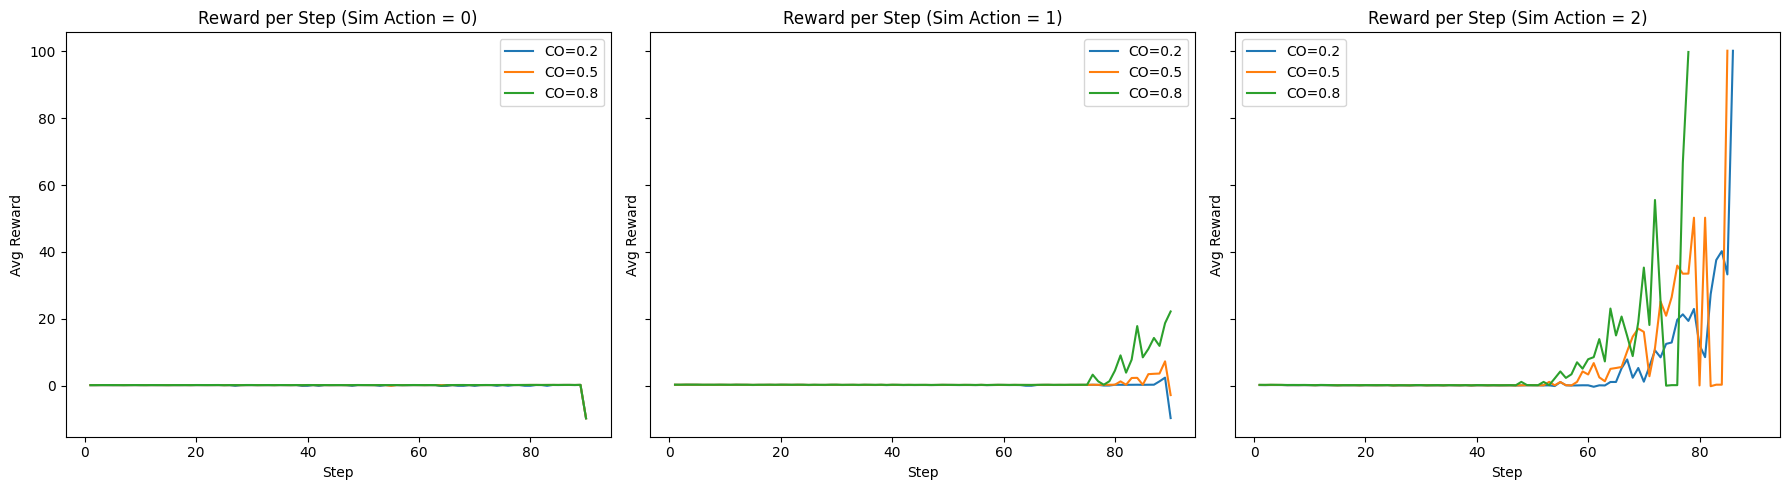

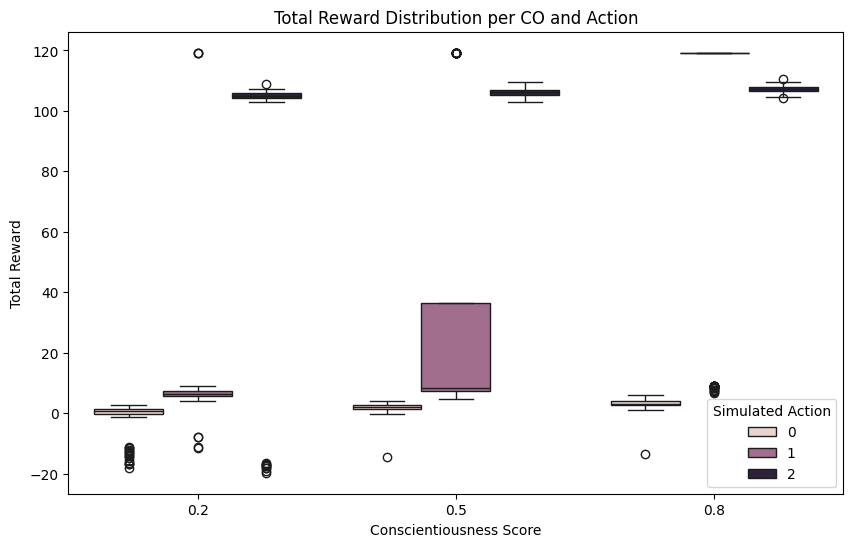

In [8]:
print("\n--- ステップごとの報酬の時系列グラフ ---")

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 6, num_rows * 5), sharex=True, sharey=True, squeeze=False)
axes = axes.flatten()

for i, action in enumerate(actions_to_plot):
    ax = axes[i]
    df_action_specific = df_steps[df_steps['simulated_action'] == action]
    plot_average_reward_time_series_subplot(
        ax=ax,
        df_steps=df_action_specific,
        co_scores=co_scores_for_plot,
        plot_title=f'Reward per Step (Sim Action = {action})',
        show_xlabel=True
    )

for j in range(len(actions_to_plot), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()



import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_episodes, x='co_score', y='total_reward', hue='simulated_action')
plt.title("Total Reward Distribution per CO and Action")
plt.xlabel("Conscientiousness Score")
plt.ylabel("Total Reward")
plt.legend(title="Simulated Action")
plt.show()



1000回試行



=== 強化学習エージェント 学習＆評価: co_score = 0.2 ===
新規モデルを作成して学習します。
Using cpu device
Logging to ./ppo_tensorboard_co0.2/PPO_run_co0.2_11
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 90       |
|    ep_rew_mean     | 1.73     |
| time/              |          |
|    fps             | 301      |
|    iterations      | 1        |
|    time_elapsed    | 6        |
|    total_timesteps | 2048     |
---------------------------------
モデル保存: ppo_jitai_agent_co0.2.zip
エピソード 1: 報酬=1.50, ステップ=90
エピソード 2: 報酬=2.01, ステップ=90
エピソード 3: 報酬=3.63, ステップ=90
エピソード 4: 報酬=1.87, ステップ=90
エピソード 5: 報酬=2.51, ステップ=90
エピソード 6: 報酬=2.14, ステップ=90
エピソード 7: 報酬=2.01, ステップ=90
エピソード 8: 報酬=3.29, ステップ=90
エピソード 9: 報酬=2.52, ステップ=90
エピソード 10: 報酬=1.91, ステップ=90
エピソード 11: 報酬=1.63, ステップ=90
エピソード 12: 報酬=2.74, ステップ=90
エピソード 13: 報酬=2.53, ステップ=90
エピソード 14: 報酬=1.59, ステップ=90
エピソード 15: 報酬=1.61, ステップ=90
エピソード 16: 報酬=2.95, ステップ=90
エピソード 17: 報酬=1.54, ステップ=90
エピソード 18: 報酬=2.28, ステップ=90
エピソード 19: 報酬=2.31, ステッ

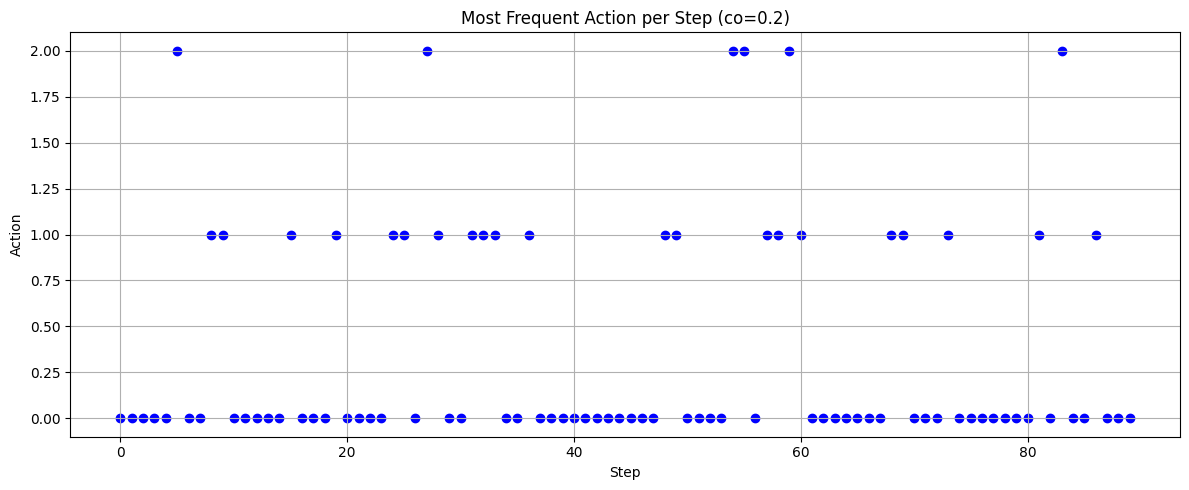

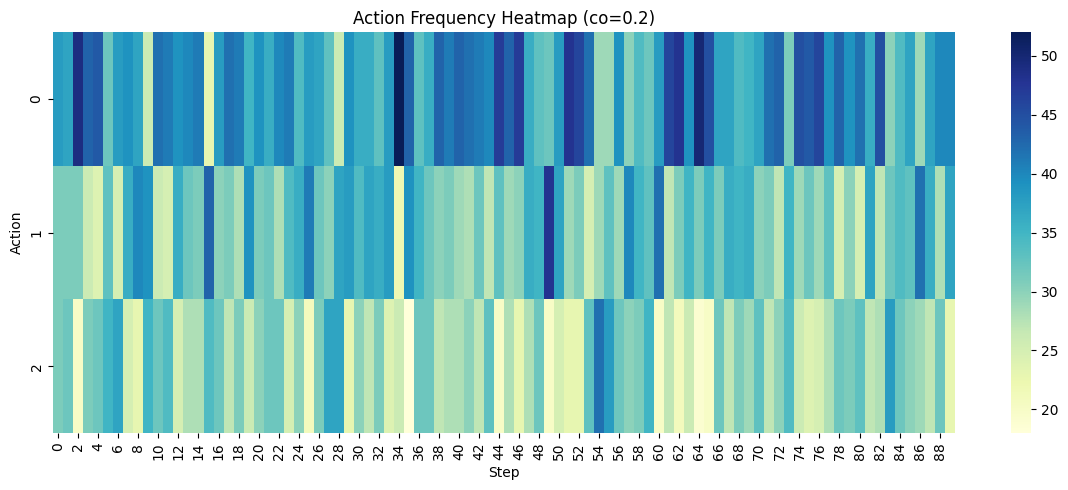


=== 強化学習エージェント 学習＆評価: co_score = 0.5 ===
新規モデルを作成して学習します。
Using cpu device
Logging to ./ppo_tensorboard_co0.5/PPO_run_co0.5_9
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 88.4     |
|    ep_rew_mean     | 70.6     |
| time/              |          |
|    fps             | 441      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2048     |
---------------------------------
モデル保存: ppo_jitai_agent_co0.5.zip
エピソード 1: 報酬=113.51, ステップ=86
エピソード 2: 報酬=113.69, ステップ=85
エピソード 3: 報酬=112.90, ステップ=87
エピソード 4: 報酬=113.50, ステップ=85
エピソード 5: 報酬=112.91, ステップ=85
エピソード 6: 報酬=114.68, ステップ=90
エピソード 7: 報酬=113.27, ステップ=82
エピソード 8: 報酬=113.67, ステップ=89
エピソード 9: 報酬=114.45, ステップ=90
エピソード 10: 報酬=112.67, ステップ=90
エピソード 11: 報酬=112.16, ステップ=85
エピソード 12: 報酬=112.75, ステップ=86
エピソード 13: 報酬=2.08, ステップ=90
エピソード 14: 報酬=3.31, ステップ=90
エピソード 15: 報酬=112.93, ステップ=89
エピソード 16: 報酬=112.11, ステップ=82
エピソード 17: 報酬=113.32, ステップ=89
エピソード 18: 報酬=3.22, ス

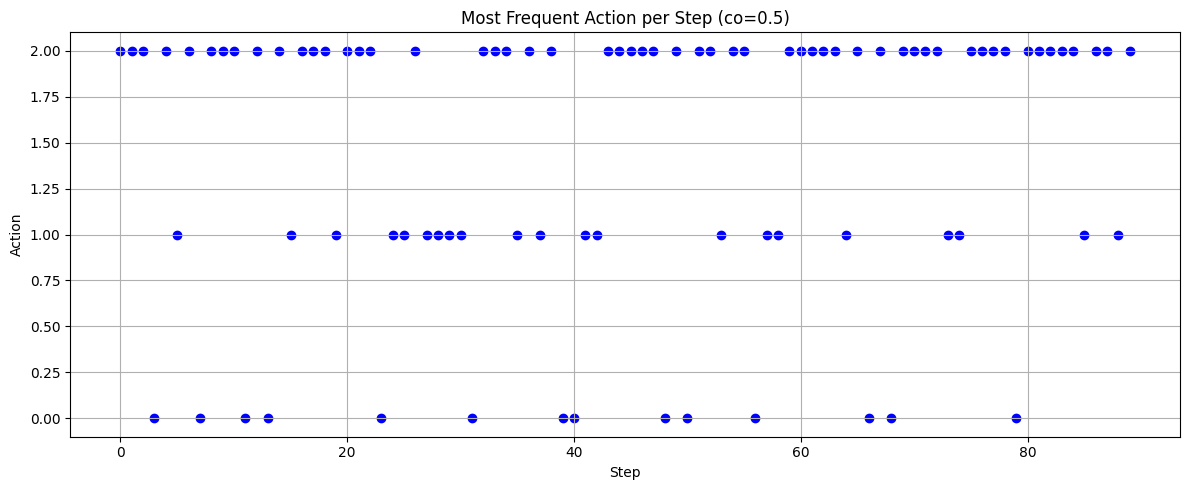

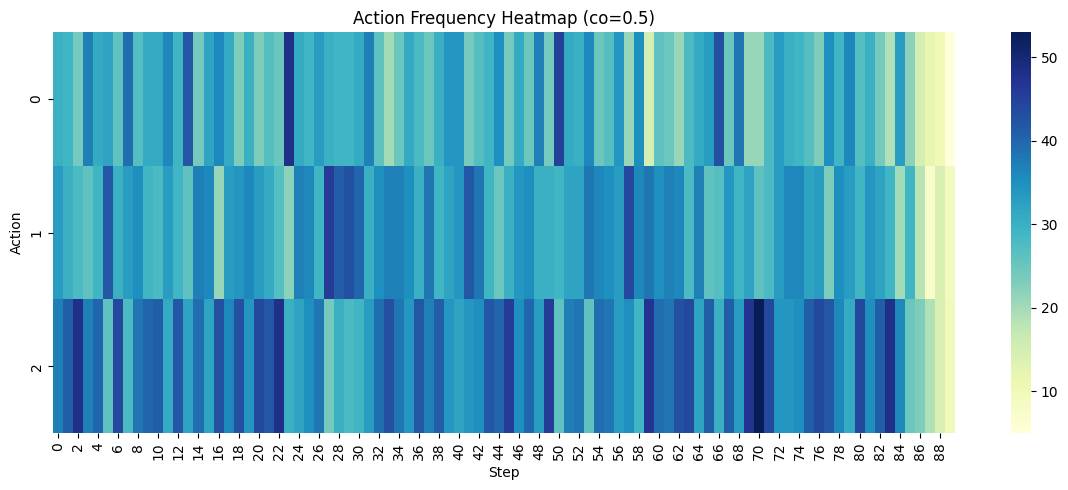


=== 強化学習エージェント 学習＆評価: co_score = 0.8 ===
新規モデルを作成して学習します。
Using cpu device
Logging to ./ppo_tensorboard_co0.8/PPO_run_co0.8_9
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 81.3     |
|    ep_rew_mean     | 114      |
| time/              |          |
|    fps             | 466      |
|    iterations      | 1        |
|    time_elapsed    | 4        |
|    total_timesteps | 2048     |
---------------------------------
モデル保存: ppo_jitai_agent_co0.8.zip
エピソード 1: 報酬=113.74, ステップ=77
エピソード 2: 報酬=113.72, ステップ=83
エピソード 3: 報酬=114.53, ステップ=83
エピソード 4: 報酬=113.16, ステップ=82
エピソード 5: 報酬=113.38, ステップ=81
エピソード 6: 報酬=113.55, ステップ=84
エピソード 7: 報酬=115.15, ステップ=86
エピソード 8: 報酬=114.58, ステップ=84
エピソード 9: 報酬=112.61, ステップ=76
エピソード 10: 報酬=114.00, ステップ=85
エピソード 11: 報酬=113.75, ステップ=75
エピソード 12: 報酬=112.99, ステップ=77
エピソード 13: 報酬=112.20, ステップ=76
エピソード 14: 報酬=114.31, ステップ=84
エピソード 15: 報酬=113.20, ステップ=75
エピソード 16: 報酬=113.80, ステップ=82
エピソード 17: 報酬=114.00, ステップ=85
エピソード 18: 報酬=113

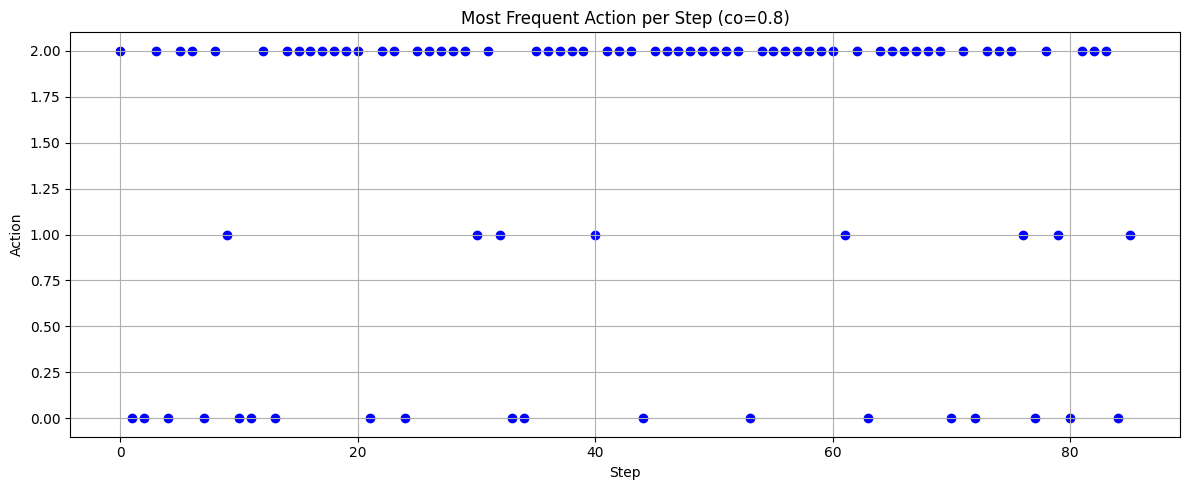

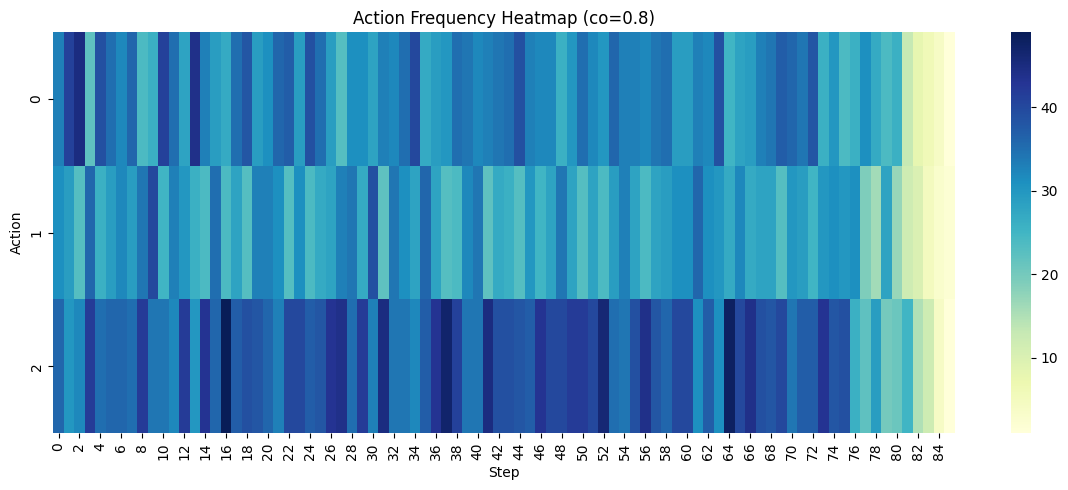

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# COスコアのリスト
co_scores = [0.2, 0.5, 0.8]

for co_score in co_scores:
    print(f"\n=== 強化学習エージェント 学習＆評価: co_score = {co_score} ===")

    # 環境設定
    rl_env_config = env_config_base.copy()
    rl_env_config["co_score"] = co_score

    def make_env_rl():
        env = SimplifiedTaskJITAIEnv(**rl_env_config)
        return Monitor(env)
    
    env_rl_vectorized = DummyVecEnv([make_env_rl])

    # モデル保存先・ログ
    model_save_path = f"ppo_jitai_agent_co{co_score}"
    tensorboard_log_path = f"./ppo_tensorboard_co{co_score}/"
    os.makedirs(tensorboard_log_path, exist_ok=True)

    # 学習 or 読み込み
    if os.path.exists(model_save_path + ".zip"):
        print(f"モデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env_rl_vectorized)
    else:
        print("新規モデルを作成して学習します。")
        model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.01, vf_coef=0.5, max_grad_norm=0.5)
        model.learn(total_timesteps=50000, tb_log_name=f"PPO_run_co{co_score}")
        model.save(model_save_path)
        print(f"モデル保存: {model_save_path}.zip")

    # 評価（100エピソード）
    num_episodes = 100
    rl_eval_step_data_list = []
    total_rewards, total_steps = 0, 0
    completed, disengaged, timed_out = 0, 0, 0

    obs = env_rl_vectorized.reset()
    for ep in range(num_episodes):
        done, ep_reward, steps = False, 0, 0
        while not done:
            action, _ = model.predict(obs, deterministic=False)
            obs, reward, done_arr, info_arr = env_rl_vectorized.step(action)
            info = info_arr[0]
            done = done_arr[0]

            rl_eval_step_data_list.append({
                'episode_id': ep, 'step': steps, 'action_taken': action[0],
                'reward': reward[0], 'D': info.get('current_D'), 'S': info.get('current_S'),
                'TP': info.get('current_TaskProgress'), 'CO': info.get('current_CO'),
                'TR': info.get('time_remaining_normalized'),
                'D_threshold_value': info.get('adjusted_D_threshold'),
                'consecutive_inaction_steps': info.get('consecutive_inaction_steps'),
                'task_completed': info.get('task_completed', False),
                'disengaged': info.get('disengaged', False),
                'TimeLimit.truncated': info.get('TimeLimit.truncated', False),
                'Habituation': info.get('current_Habituation')
            })
            ep_reward += reward[0]
            steps += 1

        total_rewards += ep_reward
        total_steps += steps
        if info.get('task_completed'): completed += 1
        elif info.get('disengaged'): disengaged += 1
        elif info.get('TimeLimit.truncated'): timed_out += 1

        print(f"エピソード {ep + 1}: 報酬={ep_reward:.2f}, ステップ={steps}")

    # --- データ保存 ---
    df = pd.DataFrame(rl_eval_step_data_list)
    csv_path = f"rl_agent_evaluation_steps_co{co_score}.csv"
    df.to_csv(csv_path, index=False)
    print(f"保存: {csv_path}")

    # --- 評価指標 ---
    print(f"\n=== 評価 (co={co_score}) ===")
    print(f"平均報酬: {total_rewards / num_episodes:.2f}")
    print(f"平均ステップ数: {total_steps / num_episodes:.2f}")
    print(f"完了率: {completed / num_episodes * 100:.1f}%")
    print(f"離脱率: {disengaged / num_episodes * 100:.1f}%")
    print(f"タイムアウト率: {timed_out / num_episodes * 100:.1f}%")

    # --- プロット1: 各ステップの最頻action ---
    mode_per_step = df.groupby("step")["action_taken"].agg(lambda x: x.value_counts().idxmax()).reset_index(name="most_frequent_action")
    plt.figure(figsize=(12, 5))
    plt.scatter(mode_per_step["step"], mode_per_step["most_frequent_action"], c='blue')
    plt.title(f"Most Frequent Action per Step (co={co_score})")
    plt.xlabel("Step"); plt.ylabel("Action")
    plt.grid(True); plt.tight_layout()
    plt.show()

    # --- プロット2: ヒートマップ ---
    action_counts = df.groupby(["step", "action_taken"]).size().reset_index(name="count")
    pivot_table = action_counts.pivot(index="action_taken", columns="step", values="count").fillna(0)
    plt.figure(figsize=(12, 5))
    sns.heatmap(pivot_table, cmap="YlGnBu", annot=False)
    plt.title(f"Action Frequency Heatmap (co={co_score})")
    plt.xlabel("Step"); plt.ylabel("Action")
    plt.tight_layout(); plt.show()

    # --- 任意：1つのエピソード詳細を可視化 ---
    # plot_single_episode_details(df, episode_id_to_plot=0, env_config=rl_env_config)

    env_rl_vectorized.close()



=== 全co_scoreの比較分析 ===


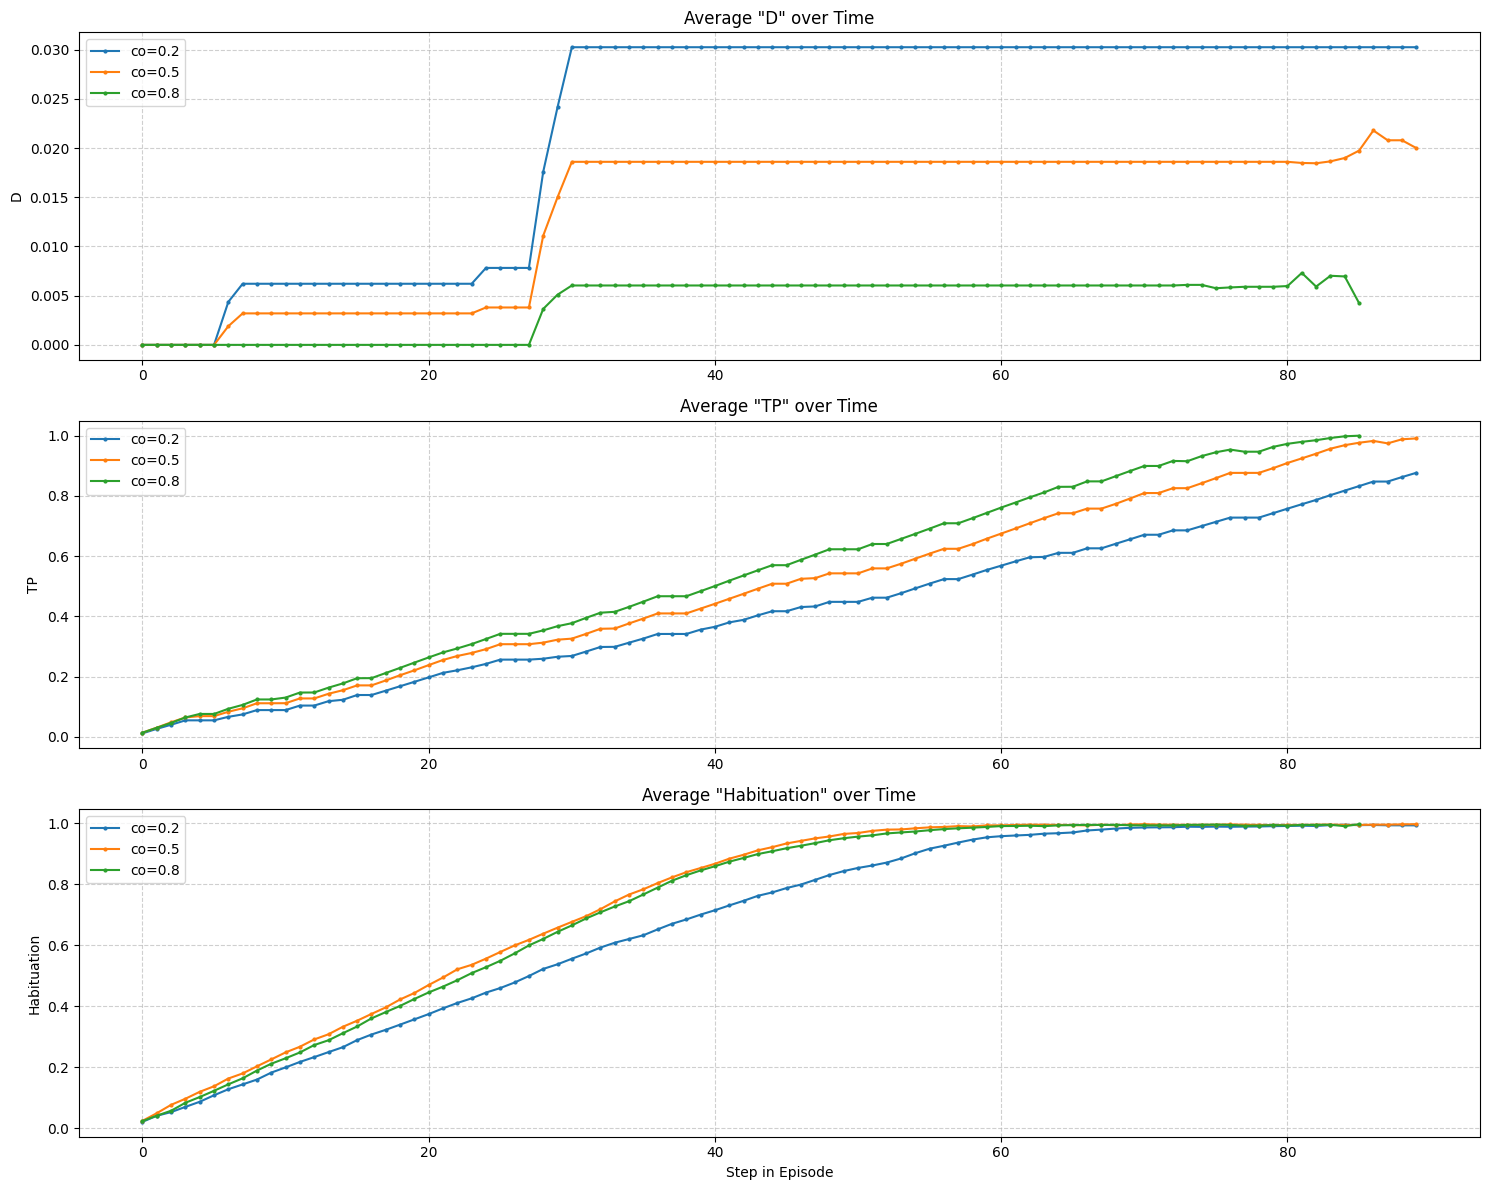

In [11]:
# for co_score in co_scores:
#   ... (ループ内の処理)
# ループがすべて終了したことを確認

# ==========================================================
# ▼▼▼▼▼▼▼▼▼▼ ここに以下の結合＆プロットコードを記述 ▼▼▼▼▼▼▼▼▼▼
# ==========================================================
print("\n=== 全co_scoreの比較分析 ===")

# --- 全ての評価結果CSVを読み込んで結合 ---
all_results_list = []
for score in co_scores:
    path = f"rl_agent_evaluation_steps_co{score}.csv"
    if os.path.exists(path):
        temp_df = pd.read_csv(path)
        all_results_list.append(temp_df)
    else:
        print(f"警告: {path} が見つかりません。")

# 結合したDataFrameが空でなければプロットを実行
if all_results_list:
    combined_df = pd.concat(all_results_list, ignore_index=True)

    # --- プロット3: 重要指標の時系列比較 ---
    metrics_to_plot = ['D', 'TP', 'Habituation']
    plt.figure(figsize=(15, len(metrics_to_plot) * 4))
    for i, metric in enumerate(metrics_to_plot):
        ax = plt.subplot(len(metrics_to_plot), 1, i + 1)
        for score in combined_df['CO'].unique():
            df_co = combined_df[combined_df['CO'] == score]
            mean_metric_per_step = df_co.groupby('step')[metric].mean()
            ax.plot(mean_metric_per_step.index, mean_metric_per_step.values, label=f'co={score}', marker='.', markersize=4)
        ax.set_title(f'Average "{metric}" over Time')
        ax.set_ylabel(metric)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend()
    plt.xlabel('Step in Episode')
    plt.tight_layout()
    plt.show()

50000試行


In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# COスコアのリスト
co_scores = [0.2, 0.5, 0.8]

for co_score in co_scores:
    print(f"\n=== 強化学習エージェント 学習＆評価: co_score = {co_score} ===")

    # 環境設定
    rl_env_config = env_config_base.copy()
    rl_env_config["co_score"] = co_score

    def make_env_rl():
        env = SimplifiedTaskJITAIEnv(**rl_env_config)
        return Monitor(env)
    
    env_rl_vectorized = DummyVecEnv([make_env_rl])

    # モデル保存先・ログ
    model_save_path = f"ppo_jitai_agent_co{co_score}"
    tensorboard_log_path = f"./ppo_tensorboard_co{co_score}/"
    os.makedirs(tensorboard_log_path, exist_ok=True)

    # 学習 or 読み込み
    if os.path.exists(model_save_path + ".zip"):
        print(f"モデル {model_save_path}.zip をロードします。")
        model = PPO.load(model_save_path, env=env_rl_vectorized)
    else:
        print("新規モデルを作成して学習します。")
        model = PPO("MlpPolicy", env_rl_vectorized, verbose=1, tensorboard_log=tensorboard_log_path,
                    learning_rate=0.0003, n_steps=2048, batch_size=64, n_epochs=10, gamma=0.99, 
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.01, vf_coef=0.5, max_grad_norm=0.5)
        model.learn(total_timesteps=50000, tb_log_name=f"PPO_run_co{co_score}")
        model.save(model_save_path)
        print(f"モデル保存: {model_save_path}.zip")

    # 評価（100エピソード）
    num_episodes = 100
    rl_eval_step_data_list = []
    total_rewards, total_steps = 0, 0
    completed, disengaged, timed_out = 0, 0, 0

    obs = env_rl_vectorized.reset()
    for ep in range(num_episodes):
        done, ep_reward, steps = False, 0, 0
        while not done:
            action, _ = model.predict(obs, deterministic=False)
            obs, reward, done_arr, info_arr = env_rl_vectorized.step(action)
            info = info_arr[0]
            done = done_arr[0]

            rl_eval_step_data_list.append({
                'episode_id': ep, 'step': steps, 'action_taken': action[0],
                'reward': reward[0], 'D': info.get('current_D'), 'S': info.get('current_S'),
                'TP': info.get('current_TaskProgress'), 'CO': info.get('current_CO'),
                'TR': info.get('time_remaining_normalized'),
                'D_threshold_value': info.get('adjusted_D_threshold'),
                'consecutive_inaction_steps': info.get('consecutive_inaction_steps'),
                'task_completed': info.get('task_completed', False),
                'disengaged': info.get('disengaged', False),
                'TimeLimit.truncated': info.get('TimeLimit.truncated', False),
                'Habituation': info.get('current_Habituation')
            })
            ep_reward += reward[0]
            steps += 1

        total_rewards += ep_reward
        total_steps += steps
        if info.get('task_completed'): completed += 1
        elif info.get('disengaged'): disengaged += 1
        elif info.get('TimeLimit.truncated'): timed_out += 1

        print(f"エピソード {ep + 1}: 報酬={ep_reward:.2f}, ステップ={steps}")

    # --- データ保存 ---
    df = pd.DataFrame(rl_eval_step_data_list)
    csv_path = f"rl_agent_evaluation_steps_co{co_score}.csv"
    df.to_csv(csv_path, index=False)
    print(f"保存: {csv_path}")

    # --- 評価指標 ---
    print(f"\n=== 評価 (co={co_score}) ===")
    print(f"平均報酬: {total_rewards / num_episodes:.2f}")
    print(f"平均ステップ数: {total_steps / num_episodes:.2f}")
    print(f"完了率: {completed / num_episodes * 100:.1f}%")
    print(f"離脱率: {disengaged / num_episodes * 100:.1f}%")
    print(f"タイムアウト率: {timed_out / num_episodes * 100:.1f}%")

    # --- プロット1: 各ステップの最頻action ---
    mode_per_step = df.groupby("step")["action_taken"].agg(lambda x: x.value_counts().idxmax()).reset_index(name="most_frequent_action")
    plt.figure(figsize=(12, 5))
    plt.scatter(mode_per_step["step"], mode_per_step["most_frequent_action"], c='blue')
    plt.title(f"Most Frequent Action per Step (co={co_score})")
    plt.xlabel("Step"); plt.ylabel("Action")
    plt.grid(True); plt.tight_layout()
    plt.show()

    # --- プロット2: ヒートマップ ---
    action_counts = df.groupby(["step", "action_taken"]).size().reset_index(name="count")
    pivot_table = action_counts.pivot(index="action_taken", columns="step", values="count").fillna(0)
    plt.figure(figsize=(12, 5))
    sns.heatmap(pivot_table, cmap="YlGnBu", annot=False)
    plt.title(f"Action Frequency Heatmap (co={co_score})")
    plt.xlabel("Step"); plt.ylabel("Action")
    plt.tight_layout(); plt.show()

    # --- 任意：1つのエピソード詳細を可視化 ---
    # plot_single_episode_details(df, episode_id_to_plot=0, env_config=rl_env_config)

    env_rl_vectorized.close()
